In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures
data = pd.read_csv('/kaggle/input/datasets/anumfatima1234/solarplatesdataset/train.csv')
data[['dc_current', 'dc_voltage']] = data[['dc_current', 'dc_voltage']].round(3)
path = '/kaggle/input/datasets/anumfatima1234/solarplatesdataset/'
# data = pd.read_csv(path + 'train.csv')   # already loaded
test = pd.read_csv(path + 'test.csv')
sample_submission = pd.read_csv(path + 'sample_submission.csv')

print(data.shape, test.shape, sample_submission.shape)
print(sample_submission.columns.tolist(), test.columns.tolist())

(44017, 7) (9617, 5) (9617, 2)
['id', 'label'] ['id', 'dc_voltage', 'dc_current', 'irradiance', 'panel_temp']


In [10]:
BASE = ["dc_voltage", "dc_current", "irradiance", "panel_temp"]   # no `day`, no `id`

class PVFeatures(BaseEstimator, TransformerMixin):
    """Physics features + 'healthy panel' residuals (fit on normal rows only)."""
    def __init__(self, normal_label="normal"):
        self.normal_label = normal_label

    def _basic(self, X):
        X = X[BASE].copy()
        X["power"]  = X.dc_voltage * X.dc_current
        X["eff"]    = X.power / X.irradiance
        X["i_irr"]  = X.dc_current / X.irradiance
        X["r"]      = X.dc_voltage / X.dc_current
        X["v_corr"] = X.dc_voltage * (1 + 0.0034 * (X.panel_temp - 25))
        return X

    def fit(self, X, y):
        X = self._basic(X)
        mask = np.asarray(y) == self.normal_label
        Z = X.loc[mask, ["irradiance", "panel_temp"]]
        self.models_ = {}
        for tgt in ["dc_current", "dc_voltage"]:
            m = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(Z, X.loc[mask, tgt])
            sd = (X.loc[mask, tgt] - m.predict(Z)).std()
            self.models_[tgt] = (m, sd)
        return self

    def transform(self, X):
        X = self._basic(X)
        Z = X[["irradiance", "panel_temp"]]
        for tgt, (m, sd) in self.models_.items():
            X["res_" + tgt] = (X[tgt] - m.predict(Z)) / sd
        return X

def make_model(seed=0):
    return Pipeline([
        ("features", PVFeatures()),
        ("clf", ExtraTreesClassifier(
            n_estimators=500, min_samples_leaf=5, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=seed)),
    ])

In [11]:
y = data["label"].values
folds = [[0, 1, 2, 3], [4, 5, 6, 7], [8, 9, 10], [11], [12]]   # keeps rare classes in training
oof = np.empty(len(data), dtype=object)

for held in folds:
    te = data["day"].isin(held).values
    m = make_model().fit(data.loc[~te, BASE], y[~te])
    oof[te] = m.predict(data.loc[te, BASE])
    print(f"held-out days {held}: macro-F1 = {f1_score(y[te], oof[te], average='macro'):.4f}")

print(f"\nDay-holdout macro-F1: {f1_score(y, oof, average='macro'):.4f}")
print(classification_report(y, oof, digits=3))

held-out days [0, 1, 2, 3]: macro-F1 = 0.9484
held-out days [4, 5, 6, 7]: macro-F1 = 0.4985
held-out days [8, 9, 10]: macro-F1 = 0.6717
held-out days [11]: macro-F1 = 0.7862
held-out days [12]: macro-F1 = 0.9771

Day-holdout macro-F1: 0.8480
               precision    recall  f1-score   support

  degradation      0.541     0.622     0.579       691
       normal      0.926     0.808     0.863     26587
 open_circuit      0.992     1.000     0.996       242
      shading      0.757     0.909     0.826     16251
short_circuit      0.964     0.988     0.976       246

     accuracy                          0.845     44017
    macro avg      0.836     0.865     0.848     44017
 weighted avg      0.858     0.845     0.846     44017



In [12]:
final = make_model().fit(data[BASE], y)

id_col, label_col = sample_submission.columns[0], sample_submission.columns[1]
pred = final.predict(test[BASE]) 

submission = pd.DataFrame({id_col: test[id_col], label_col: pred})
submission.to_csv("submission.csv", index=False)

print(submission[label_col].value_counts(normalize=True))
submission.head()

label
normal           0.575647
shading          0.312468
short_circuit    0.037746
open_circuit     0.037434
degradation      0.036706
Name: proportion, dtype: float64


,id,label
0,102668,normal
1,100729,short_circuit
2,104683,normal
3,105575,normal
4,101797,shading


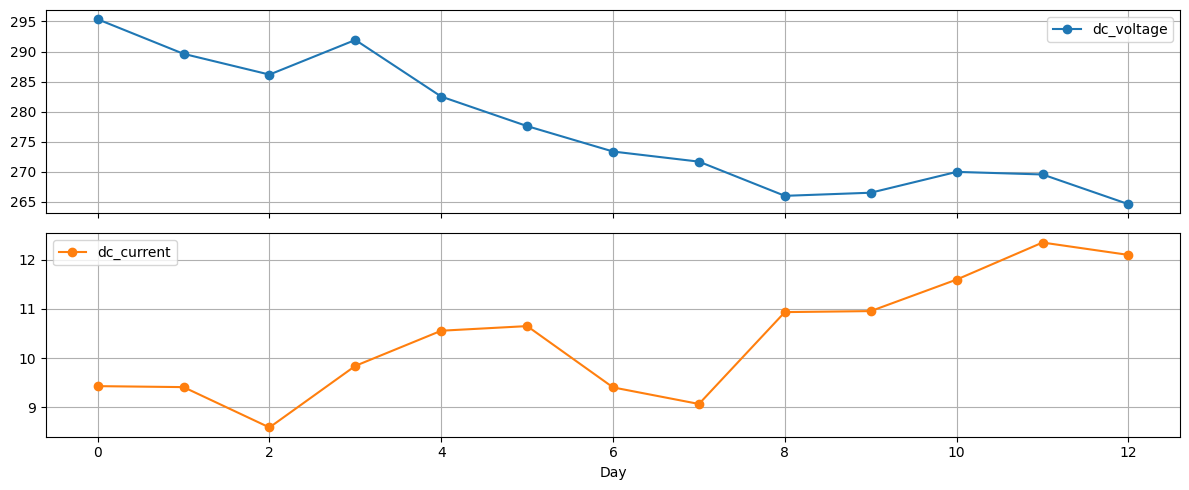

In [6]:
daily_avg = data.groupby('day')[['dc_voltage', 'dc_current']].mean()
daily_avg.plot(
    kind='line',
    marker='o',
    figsize=(12, 5),
    subplots=True,
    grid=True
) 
plt.xlabel('Day')
plt.tight_layout() 
plt.show()

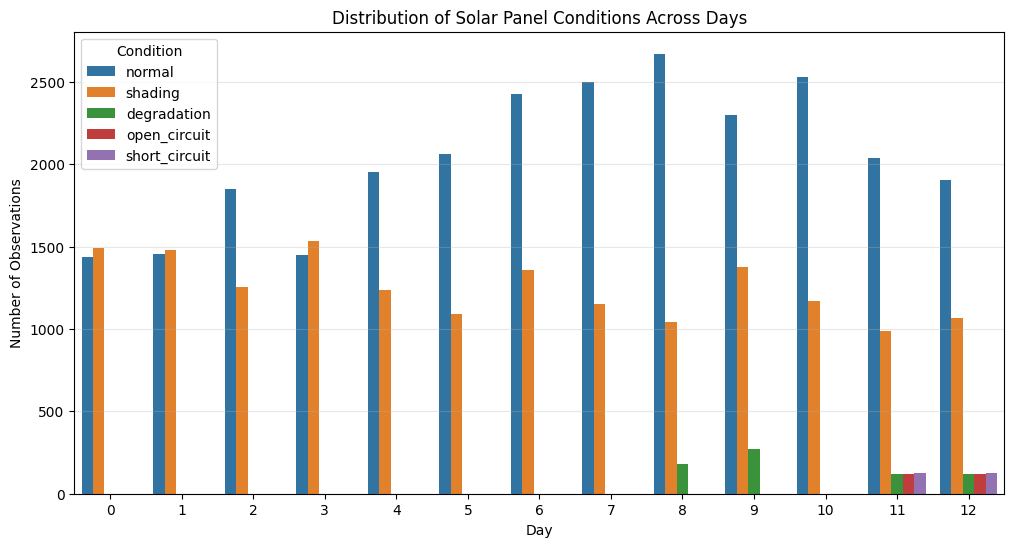

In [7]:
plt.figure(figsize=(12, 6))

sns.countplot(data=data, x='day', hue='label')

plt.title('Distribution of Solar Panel Conditions Across Days')
plt.xlabel('Day')
plt.ylabel('Number of Observations')
plt.legend(title='Condition')
plt.grid(axis='y', alpha=0.3)
plt.show()

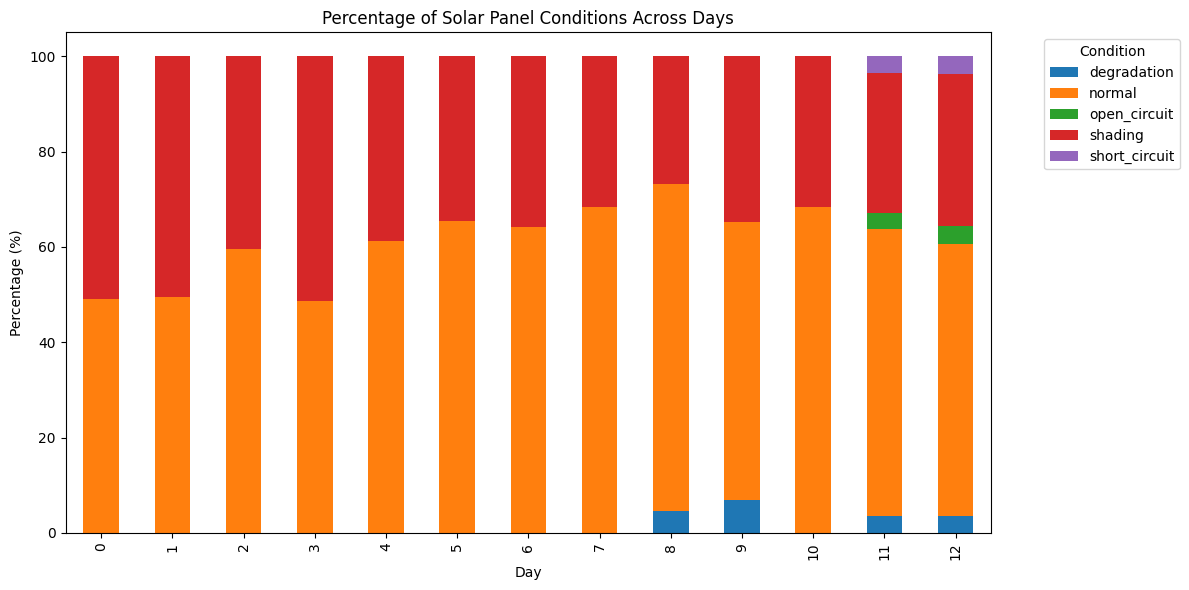

In [8]:
day_label_pct = pd.crosstab(
    data['day'],
    data['label'],
    normalize='index'
) * 100

day_label_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Percentage of Solar Panel Conditions Across Days')
plt.xlabel('Day')
plt.ylabel('Percentage (%)')
plt.legend(title='Condition', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [16]:
final = make_model().fit(data[BASE], data["label"].values)

test_pred = pd.Series(final.predict(test[BASE]), index=test["id"])

submission = sample_submission[["id"]].copy()
submission["label"] = submission["id"].map(test_pred)

assert submission["label"].notna().all(), "some sample ids are missing from test.csv"
assert len(submission) == len(sample_submission)

submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission["label"].value_counts(normalize=True))
submission.head() 

label
normal           0.576271
shading          0.312156
short_circuit    0.037746
open_circuit     0.037434
degradation      0.036394
Name: proportion, dtype: float64


,id,label
0,102668,normal
1,100729,short_circuit
2,104683,normal
3,105575,normal
4,101797,shading


In [17]:
configs = [(0, 5), (1, 10), (2, 5), (3, 10), (4, 3)]   # (seed, min_samples_leaf)

def make_et(seed, leaf):
    return Pipeline([
        ("features", PVFeatures()),
        ("clf", ExtraTreesClassifier(
            n_estimators=400, min_samples_leaf=leaf, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=seed)),
    ])

# --- optional: day-holdout check of the ensemble (takes a few minutes) ---
y = data["label"].values
folds = [[0, 1, 2, 3], [4, 5, 6, 7], [8, 9, 10], [11], [12]]
oof = np.empty(len(data), dtype=object)
for held in folds:
    te = data["day"].isin(held).values
    ms = [make_et(s, l).fit(data.loc[~te, BASE], y[~te]) for s, l in configs]
    proba = np.mean([m.predict_proba(data.loc[te, BASE]) for m in ms], axis=0)
    oof[te] = ms[0].classes_[proba.argmax(1)]
print("Ensemble day-holdout macro-F1: %.4f" % f1_score(y, oof, average="macro"))

# --- final: train on all data, average probabilities, save submission ---
final_models = [make_et(s, l).fit(data[BASE], y) for s, l in configs]
proba = np.mean([m.predict_proba(test[BASE]) for m in final_models], axis=0)
test_pred = pd.Series(final_models[0].classes_[proba.argmax(1)], index=test["id"])

submission = sample_submission[["id"]].copy()
submission["label"] = submission["id"].map(test_pred)
assert submission["label"].notna().all()
submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission["label"].value_counts(normalize=True)) 

Ensemble day-holdout macro-F1: 0.8458
label
normal           0.573880
shading          0.314235
short_circuit    0.037746
open_circuit     0.037434
degradation      0.036706
Name: proportion, dtype: float64


In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score, classification_report
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import PolynomialFeatures

BASE = ["dc_voltage", "dc_current", "irradiance", "panel_temp"]

class PVFeaturesV2(BaseEstimator, TransformerMixin):
    """Healthy-panel model (voltage/current vs irradiance + temperature) fit ONLY on normal
    rows of the data passed to fit(). Every output is a per-row calculation."""
    def __init__(self, degree=2, t_ref=25.0, normal_label="normal"):
        self.degree, self.t_ref, self.normal_label = degree, t_ref, normal_label

    def _Z(self, irr, temp):
        return pd.DataFrame({"irradiance": np.asarray(irr), "panel_temp": np.asarray(temp)})

    def fit(self, X, y):
        Xn = X.loc[np.asarray(y) == self.normal_label]
        self.m_, self.sd_ = {}, {}
        for tgt in ["dc_current", "dc_voltage"]:
            m = make_pipeline(PolynomialFeatures(self.degree), LinearRegression())
            m.fit(self._Z(Xn.irradiance, Xn.panel_temp), Xn[tgt])
            self.m_[tgt] = m
            self.sd_[tgt] = (Xn[tgt] - m.predict(self._Z(Xn.irradiance, Xn.panel_temp))).std()
        return self

    def transform(self, X):
        X = X[BASE]
        Z    = self._Z(X.irradiance, X.panel_temp)
        Zref = self._Z(X.irradiance, np.full(len(X), self.t_ref))
        Vhat, Ihat = self.m_["dc_voltage"].predict(Z), self.m_["dc_current"].predict(Z)
        Vref = self.m_["dc_voltage"].predict(Zref)
        V_c = X.dc_voltage - Vhat + Vref            # voltage restated at 25 C
        out = pd.DataFrame(index=X.index)
        out["res_V"]   = (X.dc_voltage - Vhat) / self.sd_["dc_voltage"]
        out["res_I"]   = (X.dc_current - Ihat) / self.sd_["dc_current"]
        out["V_ratio"] = X.dc_voltage / Vhat
        out["I_ratio"] = X.dc_current / Ihat
        out["V_c"]     = V_c
        out["i_irr"]   = X.dc_current / X.irradiance
        out["eff_c"]   = V_c * X.dc_current / X.irradiance   # temperature-standardised efficiency
        out["irradiance"] = X.irradiance
        return out

def make_model_v2(seed=0, n_estimators=500, leaf=5):
    return Pipeline([
        ("features", PVFeaturesV2()),
        ("clf", ExtraTreesClassifier(n_estimators=n_estimators, min_samples_leaf=leaf,
                                     max_features="sqrt", class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=seed)),
    ])

In [19]:
y = data["label"].values
folds = [[0,1,2,3],[4,5,6,7],[8,9,10],[11],[12]]
oof = np.empty(len(data), dtype=object)
for held in folds:
    te = data["day"].isin(held).values
    m = make_model_v2().fit(data.loc[~te, BASE], y[~te])
    oof[te] = m.predict(data.loc[te, BASE])
print("pooled day-holdout macro-F1: %.4f" % f1_score(y, oof, average="macro"))
print(classification_report(y, oof, digits=3))

pooled day-holdout macro-F1: 0.8763
               precision    recall  f1-score   support

  degradation      0.727     0.790     0.757       691
       normal      0.947     0.806     0.870     26587
 open_circuit      0.972     1.000     0.986       242
      shading      0.752     0.931     0.832     16251
short_circuit      0.890     0.988     0.936       246

     accuracy                          0.854     44017
    macro avg      0.858     0.903     0.876     44017
 weighted avg      0.871     0.854     0.855     44017



In [20]:
seeds = [0, 1, 2]
models = [make_model_v2(seed=s).fit(data[BASE], data["label"].values) for s in seeds]
proba = np.mean([m.predict_proba(test[BASE]) for m in models], axis=0)
test_pred = pd.Series(models[0].classes_[proba.argmax(1)], index=test["id"])

submission = sample_submission[["id"]].copy()
submission["label"] = submission["id"].map(test_pred)
assert submission["label"].notna().all(), "some sample ids are missing from test.csv"
submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission["label"].value_counts(normalize=True))

label
normal           0.564417
shading          0.323386
short_circuit    0.037746
open_circuit     0.037434
degradation      0.037018
Name: proportion, dtype: float64


In [22]:
seeds = [0, 1,2,3,4,5,6,7,8]
y_all = data["label"].values

old_models = [make_model(seed=s).fit(data[BASE], y_all) for s in seeds]
new_models = [make_model_v2(seed=s).fit(data[BASE], y_all) for s in seeds]

assert list(old_models[0].classes_) == list(new_models[0].classes_)   # same class order

p_old = np.mean([m.predict_proba(test[BASE]) for m in old_models], axis=0)
p_new = np.mean([m.predict_proba(test[BASE]) for m in new_models], axis=0)
proba = 0.5 * p_old + 0.5 * p_new                                    # simple 50/50 blend

test_pred = pd.Series(old_models[0].classes_[proba.argmax(1)], index=test["id"])

submission = sample_submission[["id"]].copy()
submission["label"] = submission["id"].map(test_pred)
assert submission["label"].notna().all(), "some sample ids are missing from test.csv"
submission.to_csv("/kaggle/working/submission.csv", index=False)
print(submission["label"].value_counts(normalize=True))

label
normal           0.573152
shading          0.314651
short_circuit    0.037746
open_circuit     0.037434
degradation      0.037018
Name: proportion, dtype: float64
